### Goals 
- Typically all graph nodes communicate with a single schema, which contains all the input and output keys/channels 
- But in some cases we want bit more controlflow 
  - Internal nodes may pass information that is not required in the graph's input/output 
  - We may also want to use different schemas for input and output for the graph

In [12]:
from typing import NotRequired, TypedDict

from IPython.display import Image, display
from langgraph.graph import END, START, StateGraph


#### Private State

In [2]:
class OverallState(TypedDict):
    foo: int


class PrivateState(TypedDict):
    ps_foo: int

In [3]:
def node_1(state: OverallState) -> PrivateState:
    print("---Node 1-----")
    return {"ps_foo": state["foo"] + 1}


def node_2(state: PrivateState) -> OverallState:
    print("----Node 2----")
    return {"foo": state["ps_foo"] + 1}

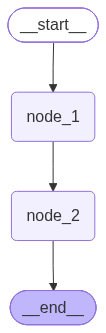

In [4]:
builder = StateGraph(OverallState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

- Node 1:The OverallState field-> `foo` is takes the initial value and it updates the PrivateState field `ps_foo` so as soon as `node_1` is executed the PrivateState field is updated 
- Node 2: The value in PrivateState field `ps_foo` is used to update the OverallState field `foo` 

In [5]:
# INFO To understand how the state changes, use stream, rather than invoking the graph directly
for chunk in graph.stream({"foo": 1}, stream_mode="values"):
    print(chunk)

{'foo': 1}
---Node 1-----
{'foo': 1, 'ps_foo': 2}
----Node 2----
{'foo': 3, 'ps_foo': 2}


### Input / Output Schema 

In [6]:
class OverallState(TypedDict):
    que: str
    ans: str
    notes: str

In [7]:
def thinking_node(state: OverallState):
    return {"ans": "bye", "notes": "... his name is Jason"}


def answer_node(state: OverallState):
    return {"ans": "bye Jason"}


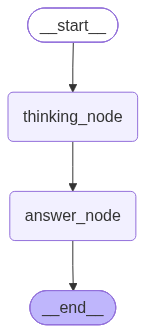

In [8]:
builder_1 = StateGraph(OverallState)
builder_1.add_node("thinking_node", thinking_node)
builder_1.add_node("answer_node", answer_node)
builder_1.add_edge(START, "thinking_node")
builder_1.add_edge("thinking_node", "answer_node")
builder_1.add_edge("thinking_node", END)
graph_1 = builder_1.compile()
display(Image(graph_1.get_graph().draw_mermaid_png()))


In [9]:
graph_1.invoke({"que": "hi, I am Jason"})

{'que': 'hi, I am Jason', 'ans': 'bye Jason', 'notes': '... his name is Jason'}

- Now add Input and Output States to the graph which will act as filters and will allow only the permitted fields

In [17]:
class InputState(TypedDict):
    question: str


class OverallState(TypedDict):
    question: str
    answer: str
    notes: str


class OutputState(TypedDict):
    answer: str


In [18]:
def thinking_node(state: InputState):
    return {"answer": "bye", "notes": "... his name is Jason"}


def answer_node(state: OverallState) -> OutputState:
    return {"answer": "bye Jason"}

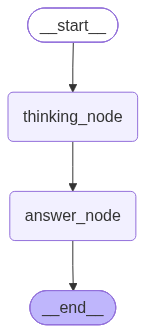

In [19]:
builder_2 = StateGraph(OverallState, input_schema=InputState, output_schema=OutputState)
builder_2.add_node("thinking_node", thinking_node)
builder_2.add_node("answer_node", answer_node)
builder_2.add_edge(START, "thinking_node")
builder_2.add_edge("thinking_node", "answer_node")
builder_2.add_edge("answer_node", END)
graph_2 = builder_2.compile()
display(Image(graph_2.get_graph().draw_mermaid_png()))

In [20]:
graph_2.invoke({"question": "hi"})

{'answer': 'bye Jason'}